In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "85bd815efd86af24338a0f0c45844cb7e1e6f155"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/85bd815efd86af24338a0f0c45844cb7e1e6f155/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Codes, Compression, and Perplexity

In that section, we interpreted entropy and
cross-entropy as average codeword lengths, suggesting that a model reaching
a loss of $x$ bits per symbol should be able to compress a text to roughly
$x$ bits per symbol. Yet we only verified that claim for one convenient
source whose surprisals happened to be whole numbers of bits; we never
constructed a code for any other distribution. Until we actually build such
a code, the connection between log-loss and file size remains an analogy.
This section closes that gap by asking two questions: can we construct a
code whose length matches a model's log-loss, and how close do practical
compressors come to that limit?

Everyday compressors already hint at the answer. Take *The Time Machine*,
the novel from that section, cleaned down to 173,428
characters over a 27-symbol alphabet (the 26 lowercase letters plus space).
The general-purpose compressor `zlib`, which replaces repeated strings with
back-references and then codes symbols individually, stores the text in
$2.84$ bits per character. By contrast, a tiny counting model that predicts
each character from the three characters before it, updating its counts as
it reads, compresses the same text to $2.55$ bits per character. Better
prediction yields a shorter file, and this section explains why. Once a
code turns log-loss into file size, a loss such as the $1.2$ nats per
character from the chapter introduction becomes a concrete storage rate,
and comparing two models becomes as direct as comparing the lengths of the
files they produce.

We build toward that result in four steps. First, we ask how short
codewords can be when a receiver must parse a binary stream with no
separators between symbols. Second, we measure the penalty of forcing
every codeword to use a whole number of bits, and we build a stream code
that avoids paying that penalty on every symbol. Third, we turn to real
text, where each character depends on the past, to see how short a file can
possibly get and how the cost of learning a model enters the total length.
Finally, we connect these code lengths to perplexity, the metric language
models report on held-out text. Throughout the section we work in bits
rather than nats because codewords are binary strings; recall that $x$ bits
equal $x \ln 2$ nats.

Alongside the book's standard imports, we need `re` for text preprocessing
and `zlib` as our baseline compressor.

In [1]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [2]:
import re
import zlib

## Symbol Codes

Let us start with the simplest communication problem. A sender observes a
stream of symbols drawn independently from a distribution $P$ over $k$
outcomes and must transmit them as a single binary string with no
separators between symbols, while the receiver must recover the original
sequence unambiguously.

### Prefix Codes and the Kraft Inequality

In a symbol code, each outcome $i$ is assigned a binary string, its
*codeword*, of length $\ell_i$. How can the receiver tell where one codeword
ends and the next begins without a delimiter? The simplest guarantee is
that no codeword is a prefix of any other; such a code is called
*prefix-free*, or simply a *prefix code*. Telephone numbers follow the same
rule: once the digits you have dialed match a valid number, no longer
number starts with that same sequence, so the exchange immediately knows
the number is complete. For four symbols, the code $0, 10, 110, 111$ is
prefix-free, and the incoming stream `110010111` can be parsed in only one
way, as `110|0|10|111`.

![The prefix-free code $0, 10, 110, 111$ as a binary tree. Each codeword is the path from the root to a leaf (left edge $0$, right edge $1$), and no codeword passes through another. A leaf at depth $\ell$ claims a fraction $2^{-\ell}$ of the tree; here the four leaves exhaust the entire budget, $2^{-1} + 2^{-2} + 2^{-3} + 2^{-3} = 1$. The symbols $a, b, c, d$ and their probabilities belong to the dyadic source from the previous section.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-kraft-tree.svg)

Visualizing a prefix code as a binary tree (the figure)
immediately reveals the constraint on codeword lengths. A codeword of
length $\ell$ ends at a leaf of depth $\ell$ and rules out every descendant
below it, claiming a fraction $2^{-\ell}$ of the full tree. Because
different codewords cannot overlap, the fractions they claim must fit
inside a single tree, a total budget of $1$, which makes short codewords
expensive. The lengths $(1, 2, 3, 3)$ in the figure spend
$\tfrac12 + \tfrac14 + \tfrac18 + \tfrac18 = 1$, using up the entire tree.
By contrast, four codewords of length $1$ would require a budget of $2$,
which is impossible since only two binary strings of length $1$ exist. The
lengths $(1, 2, 4)$ spend $\tfrac12 + \tfrac14 + \tfrac1{16} = 0.8125$ and
fit comfortably with room to spare, for example as $0, 10, 1100$.

The same tree also describes a strategy for the yes/no questions game of
that section. Each internal node poses a binary
question, and each codeword records the sequence of answers leading to a
symbol. Taking $0$ for yes, the code $0, 10, 110, 111$ asks "Is it the
first symbol?", then "Is it the second?", then "Is it the third?". The
previous section used $1$ for yes and obtained the mirror image,
$1, 01, 001, 000$.

**Proposition (Kraft inequality).** *A prefix-free binary code with
codeword lengths $\ell_1, \ldots, \ell_k$ exists if and only if*

$$
\sum_{i=1}^k 2^{-\ell_i} \leq 1.
$$

**Proof.** Associate each binary codeword $c$ of length $\ell$ with the
half-open interval $[0.c,\, 0.c + 2^{-\ell})$, consisting of all real
numbers in $[0, 1)$ whose binary expansion begins with $c$. For instance,
the codeword $10$ corresponds to $[0.10_2, 0.11_2) = [\tfrac{1}{2},
\tfrac{3}{4})$, which has width $2^{-2}$. In
the figure, this interval represents the leaf for $b$
together with the entire subtree removed beneath it. Any two such *dyadic*
intervals are either nested or disjoint: if $c$ is a prefix of $c'$, every
number starting with $c'$ also starts with $c$, so the intervals are
nested; otherwise $c$ and $c'$ disagree at some position within the shorter
length, so no number can start with both and the intervals are disjoint. A
prefix-free code therefore corresponds to disjoint intervals inside
$[0, 1)$, whose total width $\sum_i 2^{-\ell_i}$ can be at most $1$.

Conversely, suppose the lengths satisfy the equation. Sort them in
nondecreasing order, $\ell_1 \leq \cdots \leq \ell_k$, and place intervals
of width $2^{-\ell_i}$ side by side starting from $0$. The $i$-th interval
begins at $s_i = \sum_{m < i} 2^{-\ell_m}$ and ends at
$s_i + 2^{-\ell_i} \leq 1$. Because every preceding length satisfies
$\ell_m \leq \ell_i$, every term $2^{-\ell_m}$ in $s_i$ is an integer
multiple of $2^{-\ell_i}$, and hence $s_i$ itself is an integer multiple of
$2^{-\ell_i}$. The $i$-th interval is therefore the dyadic interval of the
codeword given by the first $\ell_i$ binary digits of $s_i$. Since these
intervals are disjoint, the first part of the proof guarantees that no
codeword is a prefix of another. $\blacksquare$

Notably, Kraft's budget is not an artifact of insisting on prefix-free
codes. A code is called *uniquely decodable* if every concatenation of
codewords parses in only one way, even if some codewords are prefixes of
others. McMillan proved that every uniquely decodable code must still
satisfy the equation [@McMillan.1956]
(Exercise 1). Thus any set of
codeword lengths achievable by a uniquely decodable code is already
achievable by a prefix code, so restricting our attention to prefix codes
loses nothing.

### Shannon Lengths and the Entropy Bound

Knowing the budget, we can now ask which codeword lengths minimize the
expected length $\mathbb{E}[\ell] = \sum_i p_i \ell_i$. Frequent symbols
clearly deserve shorter codewords, yet assigning a length-$1$ codeword
already consumes half of the entire Kraft budget.

To find the ideal balance, let us temporarily relax the integer constraint
and treat the lengths $\ell_i$ as real numbers. Leaving budget unspent can
never help, since shortening any codeword strictly reduces
$\mathbb{E}[\ell]$, so the optimum must satisfy $\sum_i 2^{-\ell_i} = 1$.
By Lagrange's method for equality-constrained optimization
(that section), the gradient of the objective must be
proportional to the gradient of the constraint at the minimum. The
derivative of $\mathbb{E}[\ell]$ with respect to $\ell_i$ is $p_i$, while
the derivative of $\sum_i 2^{-\ell_i}$ is $-2^{-\ell_i}\ln 2$. Hence
$2^{-\ell_i} = c\, p_i$ for a single constant $c$ across all $i$. Summing
both sides over $i$ forces $c = 1$, giving the optimal real lengths and the
resulting expected length:

$$
\ell_i = \log_2 \frac{1}{p_i},
\qquad
\mathbb{E}[\ell] = \sum_i p_i \log_2 \frac{1}{p_i} = H_2(P).
$$

Each symbol's ideal length is simply its *surprisal* $\log_2(1/p_i)$, the
self-information of that section measured in
bits, and the resulting expected length is the binary entropy $H_2(P)$. Of
course, actual codewords must have integer lengths. For the dyadic source
$P = (\tfrac12, \tfrac14, \tfrac18, \tfrac18)$, the surprisals $1, 2, 3, 3$
are already integers, so the code of the figure achieves
$\mathbb{E}[\ell] = 1.75$ bits $= H_2(P)$ with zero waste. For
$P = (0.6, 0.3, 0.1)$, the first of this chapter's running pair of
distributions, the surprisals are $0.74$, $1.74$, and $3.32$ bits.
Rounding each up to the next integer produces the *Shannon lengths*
$1, 2, 4$, the same profile that fit the binary tree with room to spare.
Its Kraft sum is $0.8125$, and its expected length is
$\mathbb{E}[\ell] = 0.6 + 0.6 + 0.4 = 1.6$ bits, compared with
$H_2(P) = 1.295$.

Even with carefully chosen integer lengths, no prefix code can beat the
entropy, and Shannon lengths never exceed it by more than one bit. Both
bounds follow from a single identity from
that section, the cross-entropy decomposition,
restated here in bits (where the subscript $2$ and superscript $(2)$ denote
base-$2$ logarithms). The expected log-loss of a model $Q$ on data drawn
from $P$ splits into the entropy of $P$ and the Kullback–Leibler
divergence from $P$ to $Q$:

$$
\textrm{CE}_2(P, Q) = -\sum_i p_i \log_2 q_i
= H_2(P) + D_{\textrm{KL}}^{(2)}(P \| Q),
\qquad D_{\textrm{KL}}^{(2)}(P \| Q) \geq 0.
$$

Here the nonnegativity of the KL divergence is Gibbs' inequality: no model
can achieve a lower expected log-loss than the true entropy of the source,
and equality holds only when $Q = P$. For our running pair, $P = (0.6, 0.3,
0.1)$ and $Q = (0.2, 0.5, 0.3)$, the three quantities are
$1.867 = 1.295 + 0.571$ bits (up to rounding in the last decimal place).

**Proposition (entropy bounds the code length).** *Let $P$ be a
distribution with $p_i > 0$ for all $i$ (symbols of zero probability need
no codeword). Every prefix-free binary code satisfies
$\mathbb{E}[\ell] \geq H_2(P)$, with equality if and only if
$p_i = 2^{-\ell_i}$ for every $i$. Conversely, the* Shannon code *with
lengths $\ell_i = \lceil \log_2 (1/p_i) \rceil$ is prefix-free and satisfies
$\mathbb{E}[\ell] < H_2(P) + 1$.*

**Proof.** For the lower bound, we compare the code against the probability
distribution it implicitly defines. Let $Z = \sum_i 2^{-\ell_i}$, which
satisfies $Z \leq 1$ by the Kraft inequality, and define the normalized
distribution $q_i = 2^{-\ell_i}/Z$. Solving for $\ell_i$ gives
$\ell_i = -\log_2 q_i - \log_2 Z$, and taking the expectation under $P$
yields

$$
\mathbb{E}[\ell] = \sum_i p_i \ell_i
= -\sum_i p_i \log_2 q_i - \log_2 Z
= H_2(P) + D_{\textrm{KL}}^{(2)}(P \| Q) - \log_2 Z
\geq H_2(P).
$$

Both excess terms are nonnegative: $D_{\textrm{KL}}^{(2)}(P \| Q) \geq 0$
by Gibbs' inequality, and $-\log_2 Z \geq 0$ because $Z \leq 1$. Equality
requires both to vanish, meaning $Q = P$ and $Z = 1$, or equivalently
$p_i = 2^{-\ell_i}$ for all $i$. For the upper bound, the Shannon lengths
satisfy $2^{-\ell_i} \leq p_i$, so $\sum_i 2^{-\ell_i} \leq \sum_i p_i = 1$;
they therefore pass Kraft's test and define a valid prefix code. Since each
ceiling adds strictly less than one bit, $\ell_i < \log_2(1/p_i) + 1$, and
averaging under $P$ gives $\mathbb{E}[\ell] < H_2(P) + 1$. $\blacksquare$

The identity the equation is even more informative
than the bound it establishes: it shows that a prefix code can waste bits
in only two ways: by implying a distribution $Q$ that differs from $P$, or
by leaving part of its Kraft budget unspent ($Z < 1$). For our running
distribution $P$, the Shannon code wastes $1.6 - 1.295 = 0.305$ bits per
symbol, of which only $0.005$ bits come from mismatch while $0.300$ bits
come from unspent budget.

Together, the two halves of the proposition sandwich the optimal expected
length of any symbol code between $H_2(P)$ and $H_2(P) + 1$ bits. This is
precisely the bound on the expected number of yes/no questions promised in
that section. The entropy floor is attained only
when every probability is an exact power of $\tfrac12$.

How much of that one-bit overhead can a smarter symbol code recover?
Huffman's algorithm [@Huffman.1952] constructs an optimal prefix code
by repeatedly merging the two least probable symbols into a single combined
symbol (Exercise 2), and it is the
symbol coder used inside `zlib`. On our running $P$, Huffman's algorithm
chooses the lengths $1, 2, 2$ and averages $1.4$ bits, just $0.1$ bits above
the entropy, eliminating two-thirds of the Shannon code's waste. Yet even an
optimal symbol code faces an unavoidable wall: no codeword can be shorter
than $1$ bit, and on a highly skewed source that single-bit floor swallows
almost the entire savings.

Consider a source that emits `a` with probability $0.9$ and `b` with
probability $0.1$. Its entropy is $0.47$ bits per symbol, and each `a`
carries only $\log_2(1/0.9) = 0.15$ bits of surprisal. Still, every symbol
code must spend at least one full bit on every `a`, more than six times its
information content. If `a` occurs with probability $0.999$, the entropy
drops to $0.011$ bits per symbol, yet any symbol code still spends $1$ bit.
That "$+1$" penalty is the cost of rounding once per symbol. Coding blocks
of $n$ symbols at a time amortizes it: treating an $n$-symbol block as a
single symbol from a larger alphabet rounds up only once per block, driving
the per-symbol overhead below $1/n$. Even coding *pairs* of `a`/`b` symbols
with Huffman's algorithm immediately lowers the rate from $1$ bit down to
$0.645$ bits per original symbol.

### Mismatched Codes and Cross-Entropy

In practice, we rarely know the true data distribution $P$; instead, we
build our code from a model $Q$. The Shannon code for $Q$ assigns lengths
$\ell_i = \lceil \log_2 (1/q_i) \rceil$, which requires $q_i > 0$ for every
symbol that $P$ can emit. When this code is used on data actually generated
by $P$, its expected length satisfies

$$
\textrm{CE}_2(P, Q) \;\leq\; \mathbb{E}_P[\ell] \;<\; \textrm{CE}_2(P, Q) + 1,
$$

because $\log_2(1/q_i) \leq \ell_i < \log_2(1/q_i) + 1$ holds for every
symbol $i$, and averaging under $P$ preserves both inequalities.
Cross-entropy is therefore the expected length of a code designed for the
model $Q$, up to a single bit of rounding, and by
the equation the KL divergence is the exact penalty paid for
using $Q$ instead of the true distribution $P$.

Let us verify these bounds numerically. The cell below constructs the
Shannon code for a model `q`, evaluates its expected length under a data
distribution `p`, and reports the Kraft sum alongside the cross-entropy. We
test both sources from this section under matched and mismatched codes: the
dyadic source paired with a uniform model, and our running $P$ paired with
$Q = (0.2, 0.5, 0.3)$.

In [3]:
def shannon_lengths(q):
    return [math.ceil(math.log2(1 / q_i)) for q_i in q]

def code_report(name, p, q):
    """The Shannon code built from q, used on data from p (all in bits)."""
    ells = shannon_lengths(q)
    kraft = sum(2 ** -ell for ell in ells)
    avg = sum(p_i * ell for p_i, ell in zip(p, ells))
    ce2 = -sum(p_i * math.log2(q_i) for p_i, q_i in zip(p, q))
    print(f'{name:<16} lengths {ells}  Kraft {kraft:.4f}  '
          f'E[ell] {avg:.3f}  CE2 {ce2:.3f}')

dyadic, uniform = [1/2, 1/4, 1/8, 1/8], [1/4] * 4
p, q = [0.6, 0.3, 0.1], [0.2, 0.5, 0.3]
code_report('dyadic, own', dyadic, dyadic)
code_report('dyadic, uniform', dyadic, uniform)
code_report('P, own', p, p)
code_report('P, code from Q', p, q)

dyadic, own      lengths [1, 2, 3, 3]  Kraft 1.0000  E[ell] 1.750  CE2 1.750
dyadic, uniform  lengths [2, 2, 2, 2]  Kraft 1.0000  E[ell] 2.000  CE2 2.000
P, own           lengths [1, 2, 4]  Kraft 0.8125  E[ell] 1.600  CE2 1.295
P, code from Q   lengths [3, 1, 2]  Kraft 0.8750  E[ell] 2.300  CE2 1.867


The two matched rows reproduce our hand calculations: here `CE2` equals
the entropy, and the expected lengths are $1.75$ and $1.6$ bits. The
mismatched rows reveal the cost of using the wrong model. Building a
Shannon code from $Q$ gives lengths $3, 1, 2$, inadvertently assigning the
longest codeword to the most frequent symbol of $P$. On data from $P$, it
averages $2.3$ bits per symbol, landing squarely inside the interval
$1.867 \leq 2.3 < 2.867$ predicted by the equation.
The uniform code assigns two bits to every symbol of the dyadic source;
nothing is rounded, so the lower bound holds with equality, and
$2.0 = 1.75 + 0.25$ bits splits cleanly into the entropy plus a KL
divergence of $0.25$ bits. Finally, the Kraft column shows how much budget
each code leaves unused: none for the dyadic source, $0.1875$ for the
Shannon code of $P$, and $0.125$ for the code built from $Q$.

Notice one subtlety: the bound the equation applies
specifically to the Shannon code of $Q$, not to every code one might build
from $Q$. Huffman's code for $Q$ has lengths $2, 1, 2$, spends the full
Kraft budget, and averages only $1.2 + 0.3 + 0.2 = 1.7 < 1.867$ bits on
data from $P$. There is no contradiction: its implied distribution is
$(\tfrac14, \tfrac12, \tfrac14)$ rather than $Q$, and that dyadic
distribution happens to sit closer to $P$. As
the equation showed, a code's excess length depends
only on the distribution it implies and its unspent budget; $Q$ matters
only through the codeword lengths it produces.

## Stream Codes and Description Length

A symbol code pays a rounding penalty on every symbol. Next we build a code
that rounds only once per message, connect it directly to a language model,
and then ask how to account for the cost of describing the model itself.

### Arithmetic Coding

Coding blocks of symbols eliminates the per-symbol rounding loss, but it
runs straight into a combinatorial wall: a codebook for blocks of $100$
binary symbols would require $2^{100}$ entries, far too many to store. What
we really want is the efficiency of a block code without its lookup table: a
single codeword for the entire message, computed on the fly from the
message itself. Codes of this kind are called *stream codes*, and
*arithmetic coding* [@Rissanen.1976; @Witten.Neal.Cleary.1987] is the
classic construction. Rather than looking up a codeword, arithmetic coding
represents the message as a subinterval of $[0, 1)$.
the figure illustrates the idea on the ten-symbol
message `aaaaaaaaba`, generated by our skewed source with
$q(\texttt{a}) = 0.9$ and encoded under the true model.

![Arithmetic coding of the message aaaaaaaaba under the model $q(\texttt{a}) = 0.9$. (a) Each symbol narrows the current interval to the subinterval allocated to it by the model; after ten symbols the remaining width is $w = 0.9^9 \cdot 0.1 = 0.0387$, the probability of the message. (b) The final interval is encoded by a dyadic interval lying wholly inside it. Neither dyadic interval of length $2^{-5}$ that overlaps it fits completely inside, whereas the interval of length $2^{-6}$ from $0.390625$ to $0.40625$ does. Its binary address 011001 is the codeword: six bits for a message whose surprisal is $4.69$ bits.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-arith-intervals.svg)

The encoder maintains a current interval, initially $[0, 1)$. To encode the
next symbol $x_i$, it partitions the current interval into one slice per
possible symbol, with widths proportional to the model's conditional
probabilities $q(\cdot \mid x_{<i})$, and keeps only the slice
corresponding to the symbol that actually occurred. Each step multiplies
the interval width by the probability of the observed symbol, so after
processing $x_1, \ldots, x_n$ the final interval has width

$$
w = \prod_{i=1}^n q(x_i \mid x_{<i}),
$$

which is exactly the probability the model assigns to the whole message.
Because distinct messages of length $n$ land in disjoint intervals, any
point inside the final interval uniquely identifies the message: a decoder
that replays the same model checks which slice contains the transmitted
number, outputs the corresponding symbol, and narrows its own interval in
lockstep. The decoder also needs to know when to stop, either by knowing $n$
in advance or by including a dedicated end-of-message symbol, and we set
that framing cost aside here. All that remains is to specify a point inside
the final interval in binary, and the dyadic intervals from the Kraft proof
do this cleanly.

Any interval of width $w$ is guaranteed to contain a dyadic interval of
length $2^{-\ell}$ once we choose $\ell = \lceil \log_2(1/w) \rceil + 1$.
Why? Because this choice ensures $2^{-\ell} \leq w/2$, so the first
multiple of $2^{-\ell}$ at or above the interval's left endpoint falls
within its left half, and the dyadic interval of length $2^{-\ell}$
starting there cannot overshoot the right endpoint. Panel (b) of
the figure shows both cases: the dyadic intervals of
length $2^{-5}$ protrude past the edges of the final interval, whereas one
of length $2^{-6}$ fits completely inside. Since
$\ell < \log_2(1/w) + 2$, the resulting codeword length satisfies

$$
\ell \;<\; \sum_{i=1}^n \log_2 \frac{1}{q(x_i \mid x_{<i})} + 2,
$$

meaning the message is encoded in its total surprisal under the model plus
at most two extra bits (for a known message length $n$). Rounding now
happens once for the entire message rather than once per symbol. Moreover,
codewords for different length-$n$ messages identify dyadic intervals
inside disjoint message intervals, so by the first half of the Kraft proof
they form a prefix code over messages. The entropy lower bound therefore
applies to whole messages just as it did to single symbols: no matter what
model we choose, the expected code length can never fall below the entropy
of the message.

Let us run this interval-narrowing procedure on `aaaaaaaaba` and compare
its length against the symbol-by-symbol Shannon code. The cell below tracks
the interval, extracts the binary codeword, verifies that its dyadic
interval fits inside the final interval, and prints both bit counts.

In [4]:
msg = 'aaaaaaaaba'                    # nine a's, one b
q = {'a': 0.9, 'b': 0.1}              # an i.i.d. model of the source

lo, hi = 0.0, 1.0
for ch in msg:                        # keep the observed symbol's slice
    width = hi - lo
    if ch == 'a':                     # 'a' owns the left 90% of the interval
        hi = lo + width * q['a']
    else:                             # 'b' owns the right 10%
        lo = lo + width * q['a']

ell = math.ceil(-math.log2(hi - lo)) + 1      # codeword length
m = math.ceil(lo * 2 ** ell)                  # first multiple of 2^-ell >= lo
assert lo <= m / 2 ** ell and (m + 1) / 2 ** ell <= hi
surprisal = -math.log2(math.prod(q[ch] for ch in msg))
shannon_bits = sum(math.ceil(math.log2(1 / q[ch])) for ch in msg)
print(f'final interval [{lo:.4f}, {hi:.4f}), width {hi - lo:.4f}')
print(f'surprisal {surprisal:.2f} bits, codeword {m:0{ell}b} ({ell} bits)')
print(f'symbol-by-symbol Shannon code: {shannon_bits} bits')

final interval [0.3874, 0.4262), width 0.0387
surprisal 4.69 bits, codeword 011001 (6 bits)
symbol-by-symbol Shannon code: 13 bits


The final width $0.0387$ matches the product $0.9^9 \cdot 0.1$ as
expected. The message has $4.69$ bits of surprisal, and arithmetic coding
stores it in $6$ bits (`011001`), whereas the symbol-by-symbol Shannon code
needs $13$ bits because it spends a full bit on each of the nine cheap
`a`'s. Because this particular string has the source's average composition
(nine `a`'s and one `b`), its surprisal equals $10\, H_2(0.9, 0.1) = 4.69$
bits; a message with two `b`'s would require more bits.

Naive floating-point narrowing only works for short messages. Since the
width shrinks by a factor $q$ at every step, after roughly a hundred
symbols the two endpoints become indistinguishable within the $53$-bit
significand of a double-precision float
(Exercise 3).
Practical arithmetic coders solve this using fixed-width integer arithmetic
and emit leading bits as soon as both endpoints agree on them, keeping the
working interval rescaled to full precision
[@Witten.Neal.Cleary.1987]. With rescaling, a message can be
arbitrarily long and the two-bit overhead vanishes per symbol: a text of
$n$ symbols is stored in $n$ times the model's average log-loss in bits.

### A Language Model as a Compressor

Nothing in arithmetic coding assumed that symbols are independent. Any
conditional model $q(\cdot \mid x_{<i})$ can drive the interval narrowing,
provided encoder and decoder compute the same next-symbol
probabilities bit for bit in finite precision. Pair an autoregressive
language model with an arithmetic coder, and you have a lossless
compressor: given a shared tokenizer, model, and coder, any document
compresses to its total surprisal under the model plus at most two bits. (A
practical file format adds minor framing overhead, and if the model itself
is fixed in advance, both sides must already possess it.)

The simplest model that learns on the fly is a counting model. An
*adaptive order-$m$ model* predicts each character from the $m$ characters
immediately preceding it, its *context* $s$, using

$$
q(x \mid s) = \frac{c(s, x) + \tfrac12}{c(s) + \tfrac{k}{2}},
$$

where $c(s, x)$ counts how many times $x$ has followed $s$ so far,
$c(s) = \sum_x c(s, x)$ is the total count for context $s$, and $k$ is the
alphabet size. Adding $\tfrac12$ to every count guarantees that no
character ever receives zero probability (which would cost infinitely many
bits). Crucially, the model updates its counts *after* coding each
character. Because the decoder performs the same updates on the
characters it has already recovered, encoder and decoder stay in lockstep
and no model parameters ever need to be transmitted.

Let us test this compressor on *The Time Machine*. The first cell downloads
and cleans the text down to lowercase letters and spaces, then defines a
function that computes the adaptive code length in bits per character.

In [5]:
fname = d2l.download(d2l.DATA_URL + 'timemachine.txt',
                     sha1_hash='090b5e7e70c295757f55df93cb0a180b9691891a')
with open(fname) as f:
    text = re.sub('[^A-Za-z]+', ' ', f.read()).lower()   # 26 letters, space

def adaptive_bits(text, m, k):
    """Bits per character of the adaptive order-m model with half counts."""
    counts, totals, bits = {}, {}, 0.0
    for i, ch in enumerate(text):
        s = text[max(0, i - m):i]                # the context
        c = counts.setdefault(s, {})
        bits -= math.log2((c.get(ch, 0) + 0.5) / (totals.get(s, 0) + k / 2))
        c[ch] = c.get(ch, 0) + 1                 # learn after coding
        totals[s] = totals.get(s, 0) + 1
    return bits / len(text)

Next we evaluate contexts of length zero through four and compare them
against `zlib` at its highest compression level. Longer contexts predict
better once their counts are populated, yet they also have far more counts
to learn; the output shows where that tradeoff turns.

In [6]:
k, n = len(set(text)), len(text)
freq = [text.count(ch) / n for ch in set(text)]
h_freq = -sum(f * math.log2(f) for f in freq)
print(f'{n} characters over {k} symbols, letter-frequency entropy '
      f'{h_freq:.3f} bits')
bits = [adaptive_bits(text, m, k) for m in range(5)]
for m, b in enumerate(bits):
    print(f'order {m}: {b:.2f} bits/char = {b * math.log(2):.2f} '
          f'nats/char, perplexity 2^bits = {2 ** b:.2f}')
print(f'zlib -9: {8 * len(zlib.compress(text.encode(), 9)) / n:.2f} bits/char')
print(f'order 0 minus the letter-frequency entropy: {bits[0] - h_freq:.4f} '
      f'bits/char, {(bits[0] - h_freq) * n:.0f} bits in all')

173428 characters over 27 symbols, letter-frequency entropy 4.078 bits


order 0: 4.08 bits/char = 2.83 nats/char, perplexity 2^bits = 16.91
order 1: 3.29 bits/char = 2.28 nats/char, perplexity 2^bits = 9.81
order 2: 2.75 bits/char = 1.90 nats/char, perplexity 2^bits = 6.70
order 3: 2.55 bits/char = 1.77 nats/char, perplexity 2^bits = 5.84
order 4: 2.78 bits/char = 1.92 nats/char, perplexity 2^bits = 6.85
zlib -9: 2.84 bits/char
order 0 minus the letter-frequency entropy: 0.0011 bits/char, 183 bits in all


Adding context drops the code length from $4.08$ bits per character with no
context down to $2.55$ bits per character with three characters of context,
beating `zlib`'s $2.84$. Adding a fourth character, however, reverses the
gain: the order-$4$ model climbs back up to $2.78$ bits per character. Most
of its $27^4 \approx 530{,}000$ possible contexts appear too rarely in the
novel for the model to learn their next-character probabilities, and every
extra bit spent while those counts warm up goes directly into the file.

By contrast, with no context at all there is very little to learn. The
first line of output reports the entropy of the novel's empirical letter
frequencies, $4.078$ bits per character, which is the rate a context-free coder would
achieve if it knew those frequencies in advance. The order-$0$ model starts
from scratch, and the final line measures the exact cost of learning them:
just $0.0011$ bits per character, or $183$ bits across the entire book.
Learning $26$ letter frequencies is cheap; learning half a million contexts
is not. (We will return to the nats and perplexity columns in
that section.)

An adaptive model avoids sending parameters, at the cost of predicting
poorly early in the file while it learns. A pretrained model takes the
opposite trade-off: it compresses every file well from the very first byte,
provided its weights have already been shared once.
@Deletang.Ruoss.Duquenne.ea.2023 demonstrate this trade-off with a
70-billion-parameter language model. Driving an arithmetic coder with its
next-token probabilities compresses ImageNet image patches to $43.4\%$ of
their raw size (compared with $58.5\%$ for PNG) and LibriSpeech audio to
$16.4\%$ (compared with $30.3\%$ for FLAC). Those figures exclude the model
itself: at two bytes per parameter, the weights occupy $140$ GB against
$1$ GB for each dataset, and once the model size is counted it no longer
beats the standard codecs.

### Minimum Description Length

In our *The Time Machine* experiment, each adaptive model paid for learning
its counts as it went. Remove that charge and the ranking flips completely:
if we first gather counts from the entire novel and then score the same
novel with those counts, order $4$ beats order $3$, order $5$ beats order
$4$, and so on, because a larger lookup table can simply memorize the text
(Exercise 4). Judged
solely by how well it fits the data in hindsight, a richer model never
loses. Yet a receiver who does not already possess the model must first be
sent its description. The *minimum description length* (MDL) principle
resolves this by choosing the model $\mathcal{M}$ that minimizes the total
code length of the model and the data together:

$$
\hat{\mathcal{M}}
=\mathop{\mathrm{argmin}}_{\mathcal{M}}
\bigl[L(\mathcal{M})+L(\mathcal{D}\mid \mathcal{M})\bigr],
$$

where $L(\mathcal{M})$ is the number of bits needed to specify the model
and $L(\mathcal{D}\mid\mathcal{M})$ is the log-loss of the data
$\mathcal{D}$ under that model, which is its code length in bits by the
previous subsections. Under MDL, a more elaborate model is preferred only
if it saves more bits on the data than it costs to describe. In this sense MDL is Occam's razor quantified in bits. Moreover,
when the model description comes from a prior distribution via
$L(\mathcal{M}) = -\log_2 P(\mathcal{M})$, minimizing the sum is
minimizing minus the log prior minus the log likelihood, so MDL coincides
with maximum a posteriori estimation (that section).

A simple coin-flipping example makes both terms concrete. Suppose
$n = 1{,}000$ flips produce $600$ heads. The fair-coin hypothesis
$\mathcal{M}_0$ has no parameters to transmit and codes each flip in $1$
bit, giving $L(\mathcal{D} \mid \mathcal{M}_0) = 1{,}000$ bits. The
biased-coin hypothesis $\mathcal{M}_1$ must first transmit its bias
$\theta$, which requires choosing a finite precision. Because the sample
proportion of heads in $n$ flips fluctuates on the scale of $1/\sqrt{n}$,
sending digits of $\theta$ finer than $1/\sqrt{n}$ wastes bits describing
sampling noise
(Exercise 5). A grid of
spacing $1/\sqrt{n}$ on $(0, 1)$ has $\sqrt{n}$ points, so naming the
closest grid point costs
$L(\mathcal{M}_1) = \log_2 \sqrt{n} = \tfrac12 \log_2 1{,}000 \approx 5$
bits. Given $\theta$, the data take
$L(\mathcal{D} \mid \mathcal{M}_1) \approx 1{,}000\, H_2(0.6, 0.4) = 971$
bits, for a total of $976 < 1{,}000$ bits. MDL therefore selects the biased
coin: spending $5$ bits on the parameter saves $29$ bits on the data. Had
we observed only $520$ heads, the data savings would be just $1.2$
bits, less than the $5$-bit parameter cost, and MDL would keep the fair coin.
Charging $\tfrac12 \log_2 n$ bits per real parameter in this fashion is
known as the *Bayesian information criterion*.

In fact, our *The Time Machine* experiment was already applying MDL. An
adaptive code length is a valid complete description of the data, with the
cost of learning the model folded directly into the bit stream. For the
order-$0$ model, that learning cost is tiny: charging
$\tfrac12 \log_2 n \approx 8.7$ bits for each of the $26$ free letter
frequencies predicts about $226$ bits, reasonably close to the $183$ bits
we actually observed (the criterion retains only the leading asymptotic
term). For the order-$4$ model, learning a separate distribution for every
observed context cost more bits than the fourth character of context saved,
so the adaptive code length automatically favored order $3$.

Notice that a naive parameter count would have missed the mark badly here.
The order-$4$ model formally has $27^4 \cdot 26 \approx 14$ million free
frequencies; at $8.7$ bits each, the Bayesian information criterion would
assess a penalty of $120$ million bits for a novel that takes only $1.4$
million bits uncompressed at eight bits per character. Parameter-counting
asymptotics assume far more data than parameters. In reality, most of those
four-character contexts never appear, and the adaptive code charges nothing
for them. Whenever a model has more parameters than data, including modern
neural networks, the adaptive code length is the description length that
remains meaningful.

## Entropy Rate and Typical Sequences

Up to now we have taken a model as given and measured the length of its
code. Now we turn the question around: for a source with memory, how short
can the code of the *best possible* model be?

### The Entropy Rate

For independent symbols, the fundamental compression floor is the
single-symbol entropy. Real text, however, is full of dependence: after `q`
comes `u`, and after `th` comes `e` or `a` far more often than `z`. To
analyze sources with memory, suppose the sequence $X_1, X_2, \ldots$ is
*stationary*, meaning that the joint distribution of any block of symbols
is unchanged when shifted in time.

We draw on the joint and conditional entropies introduced in
that section. For the remainder of this
section, $H$ denotes entropy in bits for random variables, while
$H_2(p_1, \ldots, p_k)$ continues to denote the binary entropy of an
explicit probability vector. The joint entropy $H(X_1, \ldots, X_n)$ treats
an entire $n$-symbol block as a single random variable, while the
conditional entropy
$H(X_n \mid X_{<n}) = \mathbb{E}\big[-\log_2 p(X_n \mid X_{<n})\big]$
measures the expected log-loss of the best possible next-symbol predictor,
namely the true source itself. Applying the chain rule
$H(X, Y) = H(X) + H(Y \mid X)$ repeatedly breaks the block entropy into a
sum of conditional entropies,
$H(X_1, \ldots, X_n) = \sum_{i=1}^n H(X_i \mid X_{<i})$. The *entropy rate*
of the source is the limiting conditional entropy, or equivalently the
limiting entropy per symbol of long blocks:

$$
H_{\textrm{rate}} = \lim_{n \to \infty} \frac{1}{n} H(X_1, \ldots, X_n)
= \lim_{n \to \infty} H(X_n \mid X_{<n}).
$$

Because the block entropy is the sum of $n$ conditional entropies, the
first expression is the running average of the terms whose limit appears in
the second. For any stationary source, both limits exist and coincide, and
$\tfrac1n H(X_1, \ldots, X_n)$ decreases monotonically toward
$H_{\textrm{rate}}$ [@Cover.Thomas.1999], facts we take as given. The
intuition is straightforward: conditioning never increases entropy
(that section), so each additional symbol of
context can only reduce next-symbol uncertainty, and the running average of
a nonincreasing sequence is itself nonincreasing. When symbols are
independent and identically distributed, both limits reduce immediately to
$H(X_1)$.

A two-state Markov chain shows how strongly memory lowers the floor.
Suppose the chain emits `a` or `b`, staying at its current symbol with
probability $0.9$ and switching with probability $0.1$. By symmetry, both
symbols occur equally often, so a single symbol viewed in isolation has
entropy $H(X_1) = 1$ bit. Given the previous symbol, however, the next
symbol behaves like a biased coin with probability $0.1$ of switching, so
$H(X_n \mid X_{n-1}) = H_2(0.9, 0.1) = 0.47$ bits, and looking further back
adds no new information. Memory alone cuts the fundamental floor from $1$
bit per symbol down to $0.47$
(Exercise 6 analyzes
the general asymmetric two-state chain).

For any stationary source, no uniquely decodable code can average fewer
than $H_{\textrm{rate}}$ bits per symbol. Indeed, any code for blocks of
$n$ symbols is a symbol code over the alphabet of $n$-symbol blocks; by the
entropy bound (extended to uniquely decodable codes via McMillan's
theorem), it must spend at least $H(X_1, \ldots, X_n)$ bits per block, and
monotonicity guarantees $H(X_1, \ldots, X_n) \geq n H_{\textrm{rate}}$.

Just as importantly, this floor is achievable. An arithmetic coder driven
by the source's true conditional probabilities spends strictly less than
the message's surprisal plus two bits by the equation. Since
the expected surprisal of an $n$-symbol block under its own distribution is
$H(X_1, \ldots, X_n)$, the coder averages less than
$\tfrac1n H(X_1, \ldots, X_n) + \tfrac2n$ bits per symbol, which converges
to $H_{\textrm{rate}}$ as $n$ grows.

In a classic experiment, Shannon estimated the entropy rate of printed
English to be roughly one bit per character [@Shannon.1951], far below
the $\log_2 27 = 4.75$ bits required for uniformly random letters and
spaces. Notice that any working compressor establishes an *upper* bound on
the entropy rate: our order-$3$ counting model's $2.55$ bits per character
is one such upper bound, whereas no compressor can ever prove a lower
bound. Returning to the chapter introduction, a language model with a loss
of $1.2$ nats per character achieves $1.73$ bits per character, well below
our counting model's $2.55$, yet still noticeably above Shannon's estimate
of one bit.

### Typical Sequences

So far we have bounded *average* code lengths. What does a single long
message look like, and how many likely messages actually exist? Answering
this illuminates entropy from a second angle, as an exponent counting the
set of likely messages. Nothing in the rest of the section relies on this
subsection, so you may skip it on a first reading. To keep the numbers
concrete, consider independent binary symbols that equal $1$ with
probability $0.3$, in messages of length $n = 200$.

The single most probable message is all zeros, with probability
$0.7^{200} = 2^{-103}$. A message with $60$ ones, the expected count, has
probability $0.3^{60}\, 0.7^{140} = 2^{-176.3}$, which equals $2^{-nH}$
where $H = H_2(0.3, 0.7) = 0.881$ bits; there are
$\binom{200}{60} = 2^{172.2}$ such messages. Meanwhile, the total number of
strings peaks at $100$ ones, with $2^{195.9}$ strings, but each one has
probability $2^{-225}$, so all of them combined carry only $2^{-29}$ of the
total probability mass. Most messages are unlikely, and the most likely
message is unrepresentative.

Write $x_{1:n}$ for the sequence $x_1, \ldots, x_n$. Because the symbols
are independent, the surprisal per symbol is a sample mean of i.i.d. random
variables, each with expectation $H = H_2(P)$. By the law of large numbers,
that sample mean converges in probability to its expectation:

$$
-\frac{1}{n}\log_2 P(X_{1:n})
=\frac{1}{n}\sum_{i=1}^n -\log_2 p(X_i)
\xrightarrow{P} H.
$$

For any fixed tolerance $\delta > 0$, a long message therefore has
surprisal within $n\delta$ of $nH$ bits with probability approaching one.
This phenomenon is the *asymptotic equipartition property* (AEP), and the
messages it captures form the *typical set* at tolerance $\delta$:

$$
A_\delta = \Big\{x_{1:n} :\ \Big|-\frac1n \log_2 P(x_{1:n}) - H\Big| < \delta\Big\}.
$$

**Proposition (AEP).** *Let $X_1, \ldots, X_n$ be independent draws from a
distribution $P$ on a finite alphabet with binary entropy $H$, and let
$\delta > 0$. Then: (i) $P(A_\delta) \to 1$ as $n \to \infty$; (ii) every
$x_{1:n} \in A_\delta$ satisfies
$2^{-n(H+\delta)} < P(x_{1:n}) < 2^{-n(H-\delta)}$; and (iii)
$|A_\delta| \leq 2^{n(H+\delta)}$, while
$|A_\delta| \geq (1-\eta)\,2^{n(H-\delta)}$ whenever
$P(A_\delta) \geq 1-\eta$.*

**Proof.** Part (i) is immediate from the equation, and part (ii)
simply exponentiates the defining inequality of $A_\delta$. For part (iii),
summing the bounds in (ii) over all members of $A_\delta$ yields
$1 \geq P(A_\delta) > |A_\delta|\, 2^{-n(H+\delta)}$ and
$1 - \eta \leq P(A_\delta) < |A_\delta|\, 2^{-n(H-\delta)}$, from which
both size bounds follow directly. $\blacksquare$

On the exponential scale, then, almost all probability mass concentrates on
roughly $2^{nH}$ typical sequences, each occurring with probability roughly
$2^{-nH}$. Keep in mind that "roughly" hides a factor of $2^{\pm n\delta}$,
which is substantial at finite lengths: for $n = 200$ and $\delta = 0.1$,
that slack is $2^{20}$.

The AEP leads directly to Shannon's source-coding theorem
[@Shannon.1948; @Cover.Thomas.1999]. To compress, assign each sequence in
$A_\delta$ a fixed-length index of $\lceil n(H+\delta) \rceil$ bits and
declare failure on any atypical message. The number of bits spent per
source symbol is called the *rate* of the code; here the rate is
$H + \delta$ (up to rounding), and the failure probability
$P(A_\delta^c) \to 0$. Since $\delta > 0$ can be made arbitrarily small,
every rate above $H$ is achievable. (Prepending a single flag bit and
falling back to an uncompressed copy for atypical messages makes the code
strictly lossless at the same asymptotic rate.) Conversely, any
fixed-length code of rate $R < H$ has only $2^{nR}$ codewords, so it can
represent a set $B$ of at most $2^{nR}$ messages. Choosing
$\delta < H - R$, we find

$$
P(B) \leq P(B \cap A_\delta) + P(A_\delta^c)
< 2^{nR}\, 2^{-n(H-\delta)} + P(A_\delta^c) \to 0.
$$

Thus every fixed-length code operating at a rate below $H$ fails with
probability tending to one. The same theorem holds for stationary ergodic
sources with $H_{\textrm{rate}}$ in place of $H$, a generalization we grant
without proof [@Cover.Thomas.1999].

For our Bernoulli source we can count the typical set *exactly*, since all
messages with the same number $j$ of ones share the same probability. The
cell below groups all $2^{200}$ binary strings by $j$, sums the counts and
probabilities of the groups that satisfy the typicality condition at
$\delta = 0.1$, and compares the resulting size against the benchmark
$2^{nH} = 2^{176.3}$.

In [7]:
n, p, delta = 200, 0.3, 0.1
j = np.arange(n + 1)                                 # number of ones
log_fact = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, n + 1)))])
log2_count = (log_fact[n] - log_fact[j] - log_fact[n - j]) / np.log(2)
bits_per_symbol = -(j * np.log2(p) + (n - j) * np.log2(1 - p)) / n
log2_prob_j = log2_count - n * bits_per_symbol       # log2 P(j ones)
h = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
typical = np.abs(bits_per_symbol - h) < delta
log2_size = np.logaddexp2.reduce(log2_count[typical])
prob = (2 ** log2_prob_j[typical]).sum()
print(f'H = {h:.3f} bits/symbol, nH = {n * h:.1f} bits')
print(f'typical: 2^{log2_size:.1f} of 2^{n} strings, '
      f'{j[typical].min()} <= j <= {j[typical].max()}')
print(f'probability they carry: {prob:.4f}')
print(f'bounds: {prob:.3f} * 2^{n * (h - delta):.1f} <= |A| '
      f'<= 2^{n * (h + delta):.1f}')

H = 0.881 bits/symbol, nH = 176.3 bits
typical: 2^188.8 of 2^200 strings, 44 <= j <= 76
probability they carry: 0.9893
bounds: 0.989 * 2^156.3 <= |A| <= 2^196.3


The $2^{188.8}$ typical strings, those containing between $44$ and $76$
ones, make up only one in $2^{11}$ of all binary strings, yet together they
carry probability $0.989$. Their count exceeds $2^{nH}$ by several thousand
because $\delta = 0.1$ admits strings with up to $76$ ones, which are far
more numerous than those near $60$; still, the size stays comfortably
within the proposition's bounds of $0.989 \cdot 2^{156.3}$ and
$2^{196.3}$. Let us plot both the probability and the fraction of strings
as a function of $j$ to see how cleanly they separate.

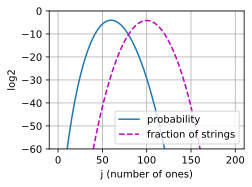

In [8]:
d2l.plot(j, [log2_prob_j, log2_count - n], 'j (number of ones)', 'log2',
         legend=['probability', 'fraction of strings'],
         ylim=[-60, 0])

The two curves peak far apart. Probability mass peaks at $j = 60$, where
strings account for only a $2^{-28}$ fraction of all possibilities; the
count of strings peaks at $j = 100$, where their combined probability is
just $2^{-29}$. The single most probable string ($j = 0$, all zeros) has
probability $2^{-103}$ and drops completely off the chart. Typical
sequences are neither the most probable strings nor the most numerous ones;
they live in the narrow band where the product of count and individual
probability is largest.

The typical set is a powerful tool for proofs, though a clumsy practical
coder. Indexing it directly costs $189$ bits for every typical string, $13$
bits above $nH = 176.3$, and fails on roughly one message in a hundred. By
contrast, arithmetic coding with the true model is strictly lossless and
averages under $nH + 2 = 178.3$ bits by the equation. What
the typical set gives us is geometric intuition: a long message almost
surely reflects the source's true composition, and roughly $2^{nH}$
messages share that composition.

## Perplexity

In practice, language models rarely report their performance as a file
size. Instead, they report a single number on held-out text, *perplexity*,
which is simply the code length of this section expressed in a different
unit.

### Perplexity as a Branching Factor

Given a text of $n$ tokens and a model assigning next-token probabilities
$q(\cdot \mid x_{<i})$, the average log-loss per token in nats and its
exponential, the *perplexity* [@Jelinek.Mercer.Bahl.ea.1977], are
defined as

$$
\textrm{CE} = -\frac{1}{n}\sum_{i=1}^n \log q(x_i \mid x_{<i}),
\qquad
\textrm{PPL} = \exp(\textrm{CE})
= \Big(\prod_{i=1}^n q(x_i \mid x_{<i})\Big)^{-1/n}.
$$

Written without distribution arguments, $\textrm{CE}$ denotes the model's
empirical loss on this particular text; its expectation over texts drawn
from the source is the cross-entropy between source and model. The second
expression shows that perplexity is the inverse geometric mean of the
probabilities assigned to the observed tokens. As introduced in
that section, perplexity has an immediate interpretation as
an *effective branching factor*: a model that spreads its probability
uniformly over $k$ tokens at every step has perplexity $k$, whereas a
perfect predictor on a deterministic sequence has perplexity $1$.

The *The Time Machine* results in that section make
this concrete on character-level text. A completely uninformed model would
guess uniformly among all $27$ symbols, giving a perplexity of $27$.
Learning letter frequencies alone cuts the perplexity to $16.91$ (roughly
$17$ equally likely choices per character), and using three characters of
context brings it down to $5.84$: on average, the model is about as
uncertain about the next character as you are about the roll of a six-sided
die. Note that our code computed perplexity as $2$ raised to the bits per
character, whereas the equation uses $e$ raised to the
nats per character; both yield the same number because
$\textrm{PPL} = b^{\textrm{CE}_b}$ for any logarithm base $b$
(Exercise 8).

### The Perplexity Floor

Just as code length cannot drop below the entropy rate, perplexity has a
fundamental floor: for a stationary source, the expected perplexity is at
least $2^{H_{\textrm{rate}}}$. Because $\textrm{CE}$ is measured in nats
while $H_{\textrm{rate}}$ in the equation is measured in
bits, a factor of $\ln 2$ converts between the two.

**Proposition (perplexity floor).** *Let $X_1, \ldots, X_n$ be drawn from a
stationary source, let $q$ be any model, and let $\textrm{CE}$ and
$\textrm{PPL}$ be the empirical loss and perplexity
the equation on this text under $q$. Then*

$$
\mathbb{E}[\textrm{CE}] \geq H_{\textrm{rate}} \ln 2,
\qquad
\mathbb{E}[\textrm{PPL}] = \mathbb{E}\big[e^{\textrm{CE}}\big] \geq 2^{H_{\textrm{rate}}}.
$$

**Proof.** Fix any prefix $x_{<i}$. The model's expected next-token loss
given $x_{<i}$ is the cross-entropy between the true conditional
distribution $p(\cdot \mid x_{<i})$ and $q(\cdot \mid x_{<i})$, which by
Gibbs' inequality is at least the conditional entropy of the source.
Averaging over prefixes gives
$\mathbb{E}[-\log q(X_i \mid X_{<i})] \geq \mathbb{E}[-\log p(X_i \mid
X_{<i})]$. Because the log-probability of a sequence decomposes as
$\log p(x_{1:n}) = \sum_i \log p(x_i \mid x_{<i})$, summing over $i$ and
dividing by $n$ yields
$\mathbb{E}[\textrm{CE}] \geq \tfrac{\ln 2}{n} H(X_1, \ldots, X_n) \geq
H_{\textrm{rate}} \ln 2$, where the second inequality follows from the
monotone decrease of the block entropy per symbol. Finally, since $e^x$ is
convex, Jensen's inequality gives
$\mathbb{E}[e^{\textrm{CE}}] \geq e^{\mathbb{E}[\textrm{CE}]}
\geq 2^{H_{\textrm{rate}}}$. $\blacksquare$

In short, no model can be less perplexed on average than the intrinsic
randomness of the source permits. If English indeed has Shannon's entropy
rate of roughly one bit per character, then no character-level model can
beat an expected perplexity of $2$, one fair coin flip per letter, putting
our order-$3$ counting model's $5.84$ well above the limit.

Notice carefully that the proposition bounds an *expectation*; the
perplexity of a single short text can easily dip below the floor. Consider
again our source that emits `a` with probability $0.9$, whose floor is
$2^H = 1.38$. Even under the true model, a ten-symbol string scores below
$1.38$ whenever it contains no `b` at all, which occurs with probability
$0.9^{10} = 35\%$. Even for a long text from this source, the perplexity
still falls below $2^H$ nearly half the time, though by a margin that
vanishes as length grows. More
generally, for an ergodic source scored by the true model, the perplexity
of a single long text converges to $2^{H_{\textrm{rate}}}$ as
$n \to \infty$, a fact we grant.

### Perplexity across Tokenizers

Because perplexity is averaged per token, its value depends directly on the
tokenizer, so two models can be compared by raw perplexity only when they
share the same tokenizer. that section demonstrates
this pitfall across three tokenizers and resolves it by dividing total
surprisal by the number of bytes in the text. In the language of this
section, that fix simply converts perplexity back into a code length per
unit of raw text. A text of $n_{\textrm{char}}$ characters split into
$n_{\textrm{tok}}$ tokens has total code length
$n_{\textrm{tok}} \log_2 \textrm{PPL}$ bits, giving

$$
\textrm{bpc} = \frac{n_{\textrm{tok}}}{n_{\textrm{char}}}\, \log_2 \textrm{PPL},
$$

where the denominator depends solely on the text itself. When every
character is one byte, as in our 27-symbol text, bits per character are
identical to the bits per byte used in the main text.

Every quantity in this section, from code length to perplexity, relies on
one crucial requirement: both encoder and decoder must be able to evaluate
the model's probability $q(x_i \mid x_{<i})$ for each symbol. When two
distributions are accessible only through samples, as when comparing a
generative model's outputs against real data, no such code exists.
that section and
that section develop ways to compare
distributions when we have only samples to work with.

## Summary

A model's log-loss is a file size once we pair it with the right
code. Any symbol-by-symbol prefix code must round each codeword to a whole
number of bits, placing its optimal expected length between $H_2(P)$ and
$H_2(P) + 1$ bits. Arithmetic coding removes that per-symbol penalty by
rounding only once per message: driven by any next-symbol model, including
an autoregressive language model, it compresses a sequence into its total
surprisal plus at most two bits. Under a mismatched model $Q$, the expected
code length is the cross-entropy $\textrm{CE}_2(P, Q)$, and the KL
divergence measures the overhead of using $Q$ instead of $P$. On
*The Time Machine*, an adaptive order-$3$ counting model compresses the
text to $2.55$ bits per character and beats `zlib`, whereas order $4$ does
worse because the bits spent learning its rarer contexts outweigh what the
extra character saves, illustrating the minimum description length principle.
For stationary sources with memory, no uniquely decodable code averages
fewer bits per symbol than the entropy rate $H_{\textrm{rate}}$. Finally,
perplexity is simply this code length exponentiated: it acts as an
effective branching factor, obeys the expected lower bound
$2^{H_{\textrm{rate}}}$, and can be compared across different tokenizers
only after converting back to bits per character or bits per byte.

## Exercises

1. **McMillan's theorem.** A code is uniquely decodable if every
   concatenation of codewords parses in only one way.
    1. Show that the code $\{0, 01, 011\}$ is uniquely decodable but not
       prefix-free, and check that it satisfies the Kraft inequality.
    1. Prove that every uniquely decodable code satisfies the Kraft
       inequality the equation. Hint: expand
       $\big(\sum_i 2^{-\ell_i}\big)^m$ as a sum over all strings of $m$
       codewords of $2^{-(\textrm{total length})}$, and group the strings
       by their total length $L$, where $m \leq L \leq m \ell_{\max}$.
       Unique decodability allows at most $2^L$ strings of total length
       $L$, so the sum is at most $m \ell_{\max}$. Take $m$-th roots and let
       $m \to \infty$.

1. **Huffman codes.** Huffman's algorithm [@Huffman.1952] builds a
   prefix code by repeatedly merging the two least probable symbols into
   one symbol of their summed probability, and then assigning $0$ and $1$
   to the two members of each merge.
    1. Run it on $P = (0.6, 0.3, 0.1)$ and on $(0.4, 0.3, 0.2, 0.1)$. Report
       the codeword lengths and the expected length of each code, next to
       the Shannon code and $H_2$.
    1. Prove that Huffman's code has the smallest expected length of all
       prefix codes. First show that in an optimal code $p_i > p_j$ implies
       $\ell_i \leq \ell_j$, and that the two longest codewords have the
       same length and can be taken to be siblings in the tree. Then show
       that merging the two least probable symbols $i, j$ reduces the
       problem by one symbol with
       $\mathbb{E}[\ell] = \mathbb{E}[\ell'] + p_i + p_j$, where $\ell'$
       are the lengths of the merged code. Conclude by induction.
       Hint: exchange two codewords and compare the expected lengths.
    1. For the source that emits `a` with probability $0.9$,
       show that every symbol code spends at least one bit per symbol. Then
       code *pairs* of symbols as a four-symbol source with Huffman's
       algorithm and check the text's $0.645$ bits per original symbol. Do
       the same for triples. How does the slack over the entropy compare
       with the bound $1/n$ in each case?
    1. Consider the linear guessing code with lengths
       $1, 2, \ldots, k-1, k-1$. Sort the probabilities,
       $p_1 \geq \cdots \geq p_k$, and show that Huffman's algorithm can
       return these lengths whenever $p_i \geq \sum_{j > i} p_j$ for every
       $i$, so that linear guessing is then an optimal prefix code. The
       source $(0.4, 0.3, 0.2, 0.1)$ violates the condition. Is linear
       guessing optimal for it?

1. [code] **Exact arithmetic coding.** ● The interval narrowing of
   that section stores `lo` and `hi` as
   floating-point numbers. Draw a message of $n = 1000$ symbols, each of
   which is `a` with probability $0.9$ and `b` otherwise.
    1. Run the floating-point narrowing on this message with the model
       $q(\texttt{a}) = 0.9$. After how many symbols does `hi - lo` first
       differ from the product of the probabilities by more than $0.1\%$,
       and after how many does it become zero? Relate both answers to the
       $53$-bit significand of a double-precision number.
    1. Repeat the narrowing with exact rationals (`fractions.Fraction`).
       Name a point of the final interval as the text's cell does, write a
       decoder that replays the model to recover the message, and compare
       the code length with the surprisal of the message and with
       $n H_2(0.9, 0.1)$.
    1. Encode the same message with the mismatched model
       $q(\texttt{a}) = 0.7$. Compare the increase in code length with
       $n D_{\textrm{KL}}^{(2)}(P \| Q)$. Why do the two numbers differ for
       a single message?

1. [extended] **Adaptive context-model compression.** ●● The text's
   `adaptive_bits` is a complete description length in the sense of
   the equation, with the cost of learning the model inside it.
   By the equation, an arithmetic coder driven by its
   predictions spends at most two bits more. @Blier.Ollivier.2018
   use such prequential codes to measure the description length of deep
   networks.
    1. Extend the text's experiment to $m = 0, 1, \ldots, 8$. For each $m$,
       compare the adaptive code length with the per-character
       cross-entropy of the order-$m$ model whose counts are taken from the
       entire text, and with `zlib`.
    1. Explain why the adaptive code length has a minimum over $m$ while
       the cross-entropy of the fitted model keeps falling. Which order does
       MDL select? Which term of the equation does the cross-entropy
       of the fitted model leave out?
    1. Design an adaptive model that combines contexts of several orders,
       for example by falling back to shorter contexts when a long context
       has few counts. Report a table of bits per character for every model
       you tried, together with `zlib`, and a paragraph on the design choice
       that mattered most.

1. **Two-part code for a coin.** ● A sequence $\mathcal{D}$ of $n$ coin
   flips contains $j$ heads, and $\hat\theta = j/n$. Hypothesis
   $\mathcal{M}_0$ is the fair coin: it has no parameter to describe, and
   $L(\mathcal{D} \mid \mathcal{M}_0) = n$ bits. Hypothesis
   $\mathcal{M}_1$ is a coin with bias $\theta$. Its encoder sends the point
   $\theta_q$ nearest to $\hat\theta$ on a grid of spacing $\Delta$ in
   $(0, 1)$, which costs $L(\mathcal{M}_1) = \log_2(1/\Delta)$ bits, and the
   decoder knows $n$ and $\Delta$.
    1. Use the decomposition the equation to show that
       $L(\mathcal{D} \mid \mathcal{M}_1) = n H_2(\hat\theta, 1 - \hat\theta)
       + n D_{\textrm{KL}}^{(2)}(\hat\theta \,\|\, \theta_q)$, where the KL
       divergence is that of the Bernoulli distributions with these
       parameters. In nats, this KL divergence is
       $(\theta_q - \hat\theta)^2 / \big(2\hat\theta(1 - \hat\theta)\big)$
       to second order. Derive the expansion, and show that the total
       length the equation of $\mathcal{M}_1$ exceeds
       $n H_2(\hat\theta, 1 - \hat\theta)$ by at most about
       $\log_2(1/\Delta) + n\Delta^2 /
       \big(8\hat\theta(1 - \hat\theta) \ln 2\big)$ bits.
    1. Which spacing $\Delta$ minimizes this bound? The decoder must know
       $\Delta$ before it decodes $\theta_q$. Why can the code therefore not
       use the minimizer? Show that the spacing $\Delta = 1/\sqrt{n}$, which
       depends on $n$ alone, gives an excess of
       $\tfrac{1}{2}\log_2 n + O(1)$ bits whenever $\hat\theta$ stays
       bounded away from $0$ and $1$.
    1. Take $n = 1000$ and the approximation
       $L(\mathcal{M}_1) + L(\mathcal{D} \mid \mathcal{M}_1) \approx
       n H_2(\hat\theta, 1 - \hat\theta) + \tfrac{1}{2}\log_2 n$ bits. The
       text showed that $\mathcal{M}_1$ wins at $j = 600$ by $24$ bits.
       Which hypothesis wins at $j = 520$? Approximately how far from $n/2$ must $j$ lie for
       $\mathcal{M}_1$ to win, and how many standard deviations $\sqrt{n}/2$
       of $j$ under the fair coin is that?

1. **Entropy rate of a two-state chain.** A chain on $\{\texttt{a},
   \texttt{b}\}$ moves from `a` to `b` with probability $0.1$ and from `b`
   to `a` with probability $0.3$, and it starts from its stationary
   distribution.
    1. Find the stationary distribution and $H(X_1)$ in bits.
    1. Show that $H(X_n \mid X_{n-1}) = \sum_s \pi_s H_2(r_s, 1 - r_s)$
       bits, where $\pi$ is the stationary distribution and $r_s$ is the
       exit probability of state $s$, and that the entropy rate equals this
       value. Compute it.
    1. Show that $\tfrac1n H(X_1, \ldots, X_n) = \tfrac1n\big(H(X_1) +
       (n-1) H_{\textrm{rate}}\big)$ and that it decreases to
       $H_{\textrm{rate}}$.
    1. Consider two limits. With both exit probabilities equal to
       $\tfrac12$ the chain is i.i.d. and the rate is $1$ bit. With both
       exit probabilities equal to $r$, the rate tends to $0$ as $r \to 0$,
       while $H(X_1)$ stays at $1$ bit. What does $H(X_1)$ say about how
       well the chain compresses?
    1. [code] Simulate $10^5$ steps of the first chain and code them with
       the text's `adaptive_bits` at orders $0$, $1$ and $2$. Which orders
       reach the rate, and what does the order-$0$ length converge to?

1. [code] **Typical and high-probability sets.** ● The code of
   that section declares a binary string of length $n = 200$
   from a Bernoulli source with $p = 0.3$ typical when its surprisal per
   symbol lies within $\delta = 0.1$ bit of the entropy $H$ in bits. It
   finds $2^{188.8}$ typical strings, inside the bounds
   $0.989 \cdot 2^{156.3} \leq |A_\delta| \leq 2^{196.3}$ of the AEP
   proposition and well above $2^{nH} = 2^{176.3}$.
    1. Which string is the most probable one? Compute its surprisal per
       symbol and decide whether it is typical. Why does this string not
       matter for compression?
    1. Let $A$ be the typical set and let $B$ be any set of strings with
       $P(B) \geq 1 - \eta$. Show that
       $P(A \cap B) \geq 1 - \eta - P(A^c)$, and conclude that
       $|B| \geq \big(1 - \eta - P(A^c)\big)\, 2^{n(H - \delta)}$.
    1. The smallest set with probability at least $0.9$ collects strings in
       order of decreasing probability. Group the strings by their number
       $j$ of ones, as the code does, and compute $\tfrac{1}{n}\log_2$ of
       the size of this set for $n = 200$, $1000$, $5000$, and $20000$.
       Compare it with $H$ and with $\tfrac{1}{n}\log_2 |A_\delta|$ at the
       same $n$. Which of the two sets grows like $2^{nH}$, and why does
       the typical set with a fixed $\delta$ not?

   *Adapted from David Tse,
   [EE376A/Stats376A: Information Theory, Homework 2](https://web.stanford.edu/~kedart/ee376a_winter1617/hw2.pdf),
   Problem 6.*

1. **Perplexity across tokenizers.** Perplexity is computed per token, so
   it depends on how a text is split into tokens.
    1. Show that $b^{\textrm{CE}_b}$ is the same number for every log base
       $b$, where $\textrm{CE}_b$ is the per-token cross-entropy in
       base-$b$ units.
    1. Two language models are evaluated on the same text of $10^6$
       characters. The tokenizer of model A splits it into
       $2.5 \times 10^5$ tokens, and A reaches a per-token perplexity of
       $20$. The tokenizer of model B splits it into $6.7 \times 10^5$
       tokens, and B reaches a per-token perplexity of $8$. Convert both
       results to bits per character with the equation. Which model
       predicts the text better?
    1. Take the entropy rate of the text to be one bit per character, the
       estimate of @Shannon.1951 . By the equation the
       expected per-token perplexity is at least $2^{H}$, where $H$ is the
       entropy rate per *token* in bits. What is the lowest perplexity any
       model can reach in expectation with the tokenizer of A, and with
       that of B? How far is each model from its floor?
    1. Explain in two sentences why the two perplexities cannot be compared
       directly while the two values of bits per character can.

[Discussions](https://d2l.discourse.group/t/36865)